## 1. Титульный лист

# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices — Advanced Regression Techniques  
**Выполнил:** Черепанов В.С.
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин И.С.  
**Репозиторий:** https://github.com/CherepanovVyacheslav/ml-course-cherepanov  
**Путь:** `module-2-house-prices/notebook.ipynb`  
**Дата:** 28.10.2026

## 2. Введение

В работе решается задача прогнозирования **цены продажи жилого дома** по его характеристикам. В отличие от классификации, где модель выбирает категорию («дорогой»/«дешёвый»), здесь результатом является непрерывное число — стоимость в долларах США. Сами признаки неоднородны: числовые (площадь, год постройки), порядковые (оценка качества) и номинальные (район и тип здания).

Под ML-проектом понимаю цепочку действий от изучения исходной таблицы до проверки модели на объектах, которых она не видела при обучении. В этой цепочке важно не только получить хороший результат, но и сохранить способ преобразования признаков, чтобы одинаково обрабатывать новые данные. Отдельно проверяется, насколько стабильны оценки на разных обучающих подвыборках.

**Основная метрика — RMSE в логарифмической шкале.** Она сильнее MAE штрафует большие ошибки и согласуется с логарифмической целевой переменной. MAE в долларах легче объяснить практически, а $R^2$ показывает долю объяснённой вариации и нужен для сравнения с порогом 0,90 из задания. Все три показателя рассматриваются вместе: высокий $R^2$ сам по себе не гарантирует малых ошибок в долларах.

**Задачи:**
1. Выполнить EDA, изучить пропуски, выбросы и распределение `SalePrice`.
2. Обучить Linear Regression, Ridge, Lasso и ElasticNet, подобрать гиперпараметры с помощью кросс-валидации; ориентир по $R^2$ — не менее 0,90.
3. Создать функцию `predict_price()`, проверить её на пяти разных домах и организовать сохранение / повторную загрузку моделей.

## 3. Теоретическая часть

**Регрессия.** Регрессионный алгоритм учится оценивать число по набору характеристик объекта. Например, в этой работе целевая переменная — цена продажи, а в других задачах это могут быть расход электричества или длительность доставки. От классификации регрессия отличается типом ожидаемого ответа: число вместо метки класса. Для линейной регрессии прогноз получается как сумма коэффициентов, умноженных на значения признаков, плюс свободный член. Если признаки сильно связаны между собой, отдельные коэффициенты могут оказаться неустойчивыми.

**Пропуски (NaN).** Отсутствие значения не всегда означает ошибку: пустое поле `PoolQC` часто говорит, что бассейна нет. MCAR — пропуск не связан с наблюдаемыми и скрытыми характеристиками; MAR — его появление объясняется доступными переменными; MNAR — зависит от самого скрытого значения. В таблицах с недвижимостью встречаются и смысловые пропуски («нет подвала»), и действительно неизвестные значения, например ширина фасада. Поэтому универсальная подстановка нуля была бы неудачным решением: для `LotFrontage` используем медиану по району, для отсутствующих объектов — отдельную категорию, а для оставшихся полей — статистики обучающей выборки.

**Регуляризация.** При большом количестве коррелирующих признаков обычная линейная регрессия может подобрать чрезмерно большие коэффициенты. Ridge (L2) добавляет штраф за сумму квадратов коэффициентов и обычно делает оценки стабильнее, но редко обнуляет их. Lasso (L1) использует сумму модулей и способен занулить часть параметров, выполняя отбор признаков. ElasticNet сочетает оба штрафа, что полезно, если есть группы похожих признаков. Силу регуляризации определяем кросс-валидацией, не подглядывая в итоговую проверочную выборку.

**Логарифмирование.** Цены имеют длинный правый хвост: дорогих домов мало, но они сильно влияют на квадратичную ошибку. Преобразование `np.log1p(SalePrice)` уменьшает перекос и позволяет модели оценивать скорее относительные, чем абсолютные различия. Формула `log1p(x)` равна $\ln(1+x)$ и определена также при нуле. Чтобы представить прогноз в долларах, применяем обратное преобразование `np.expm1()`.

**Feature Engineering.** Некоторые отношения между признаками удобнее дать модели явно. Например, сумму площадей этажей и подвала назовём `TotalSF`, а возраст дома на дату продажи — `HouseAge`. Параметр `TotalBath` учитывает полные и половинные санузлы. Также полезны бинарные признаки, фиксирующие гараж, камин и второй этаж. Новые признаки не должны использовать информацию о целевой переменной и должны вычисляться тем же способом для будущего дома.

**Метрики и кросс-валидация.** MSE — среднее квадратов ошибок, поэтому редкие крупные промахи особенно заметны. RMSE — корень из MSE; измеряется в единицах прогнозируемого значения. MAE — среднее абсолютных ошибок, оно менее чувствительно к выбросам. Коэффициент $R^2$ показывает улучшение по сравнению с прогнозом постоянного среднего целевой переменной и может быть отрицательным. При $K$-fold кросс-валидации данные обучения делятся на $K$ частей, модель многократно обучается на $K-1$ частях, а качество оценивается на оставшейся. Итоговый holdout не участвует ни в обучении, ни в выборе параметров.

$$MSE=\frac{1}{n}\sum_{i=1}^n(y_i-\hat y_i)^2$$

$$RMSE=\sqrt{MSE} \qquad MAE=\frac{1}{n}\sum_{i=1}^n|y_i-\hat y_i|$$

$$R^2=1-\frac{\sum_{i=1}^n(y_i-\hat y_i)^2}{\sum_{i=1}^n(y_i-\bar y)^2}$$

| Метод | Особенность | Важное ограничение |
|---|---|---|
| Linear Regression | Базовая оценка без штрафа | Чувствительность к мультиколлинеарности |
| Ridge | L2-сжатие коэффициентов | Не делает явный отбор признаков |
| Lasso | L1-сжатие, разреженные коэффициенты | При корреляции признаков выбор может меняться |
| ElasticNet | Совмещает L1 и L2 | Требуется подбор двух параметров |

## 4. Описание данных

**Источник:** [Kaggle — House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data). Исходный набор содержит 1460 обучающих объектов с 81 столбцом (`Id`, 79 признаков и `SalePrice`), а конкурсный `test.csv` — 1459 объектов без ответов. Дома находятся в Эймсе (Айова); данные включают площадь, качество материалов, район и историю строительства.

**Примеры признаков:**

| Поле | Содержание | Тип |
|---|---|---|
| `OverallQual` | Общее качество строения, шкала 1–10 | Числовой / порядковый |
| `GrLivArea` | Жилая площадь над землёй, кв. футы | Числовой |
| `TotalBsmtSF` | Общая площадь подвала | Числовой |
| `Neighborhood` | Район города | Номинальный |
| `YearBuilt` | Год строительства | Числовой |
| `LotFrontage` | Длина фасада вдоль улицы | Числовой, с пропусками |
| `SalePrice` | Цена продажи, доллары США | Целевая |


In [2]:
# Загрузка библиотек; версии фиксируются в requirements.txt.
from pathlib import Path
import json
import time
import warnings
import requests
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Инструменты разбиения, стандартизации и оценки качества.
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

# Для запуска требуется рабочий каталог module-2-house-prices/.
DATA_DIR = Path("data")
MODEL_DIR = Path("models")
EXAMPLES_DIR = Path("examples")
for directory in (DATA_DIR, MODEL_DIR, EXAMPLES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Резервный источник идентичных конкурсных CSV, если их ещё нет локально.
DATA_MIRROR = "https://raw.githubusercontent.com/Rswcf/houseprices_kaggle/master"
for filename in ("train.csv", "test.csv"):
    target = DATA_DIR / filename
    if not target.is_file():
        try:
            response = requests.get(f"{DATA_MIRROR}/{filename}", timeout=30)
            response.raise_for_status()
            target.write_bytes(response.content)
            print(f"Скачан {target}")
        except requests.RequestException as error:
            raise FileNotFoundError(
                f"Не удалось получить {filename}. Скачайте CSV с Kaggle и "
                f"поместите в {DATA_DIR.resolve()}. Исходная ошибка: {error}"
            ) from error

# Чтение исходных файлов, без промежуточного кодирования и очистки.
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
print("Размеры train/test:")
print(train_df.shape, test_df.shape)
assert train_df.shape == (1460, 81) and test_df.shape == (1459, 80)
print("Первые строки:")
display(train_df.head(3))

Размеры train/test:
(1460, 81) (1459, 80)
Первые строки:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [3]:
# Сводная информация о датасете: типы, пропуски, распределение целевой.
train_df.info()
display(train_df.describe(include="all").T.head(15))
missing_info = pd.DataFrame({
    "Пропущено": train_df.isna().sum(),
    "Доля, %": (100 * train_df.isna().mean()).round(2),
})
display(missing_info[missing_info["Пропущено"] > 0].sort_values("Пропущено", ascending=False))

# Точные статистики рассчитываются по реально загруженным строкам.
price = train_df["SalePrice"]
print(f"Средняя цена: ${price.mean():,.0f}; медиана: ${price.median():,.0f}")
print(f"Асимметрия SalePrice: {price.skew():.3f}; эксцесс: {price.kurtosis():.3f}")
print(f"Числовых столбцов: {len(train_df.select_dtypes(include='number').columns)}")
print(f"Категориальных столбцов: {len(train_df.select_dtypes(exclude='number').columns)}")

# Составляем отдельное описание датасета для GitHub.
lines = ["# Датасет House Prices", "", f"Источник: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data", "", f"Train: {train_df.shape}; test: {test_df.shape}", "", f"Средняя цена: ${price.mean():,.0f}", f"Медианная цена: ${price.median():,.0f}", f"Асимметрия: {price.skew():.3f}", "", "| Признак | Тип | Пропусков, % |", "|---|---|---:|"]
for column in train_df.columns:
    lines.append(f"| `{column}` | {train_df[column].dtype} | {100*train_df[column].isna().mean():.2f} |")
(DATA_DIR / "house_prices_info.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("Описание записано в data/house_prices_info.md")

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
Street,1460,2,Pave,1454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alley,91,2,Grvl,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotShape,1460,4,Reg,925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LandContour,1460,4,Lvl,1311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Utilities,1460,2,AllPub,1459,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Пропущено,"Доля, %"
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Средняя цена: $180,921; медиана: $163,000
Асимметрия SalePrice: 1.883; эксцесс: 6.536
Числовых столбцов: 38
Категориальных столбцов: 43
Описание записано в data/house_prices_info.md


## 5. Подготовка данных и EDA

В начале полезно проверить форму распределения цен и зависимость от площади. Для недвижимости `NaN` имеет два разных смысла: отсутствие объекта (например, бассейна) и неизвестное измерение (например, фасада). Сначала рассмотрим исходные данные, затем разделим строки на обучающую и проверочную выборки. Все медианы, моды, признаки и масштабирование определяются только по обучающей части.

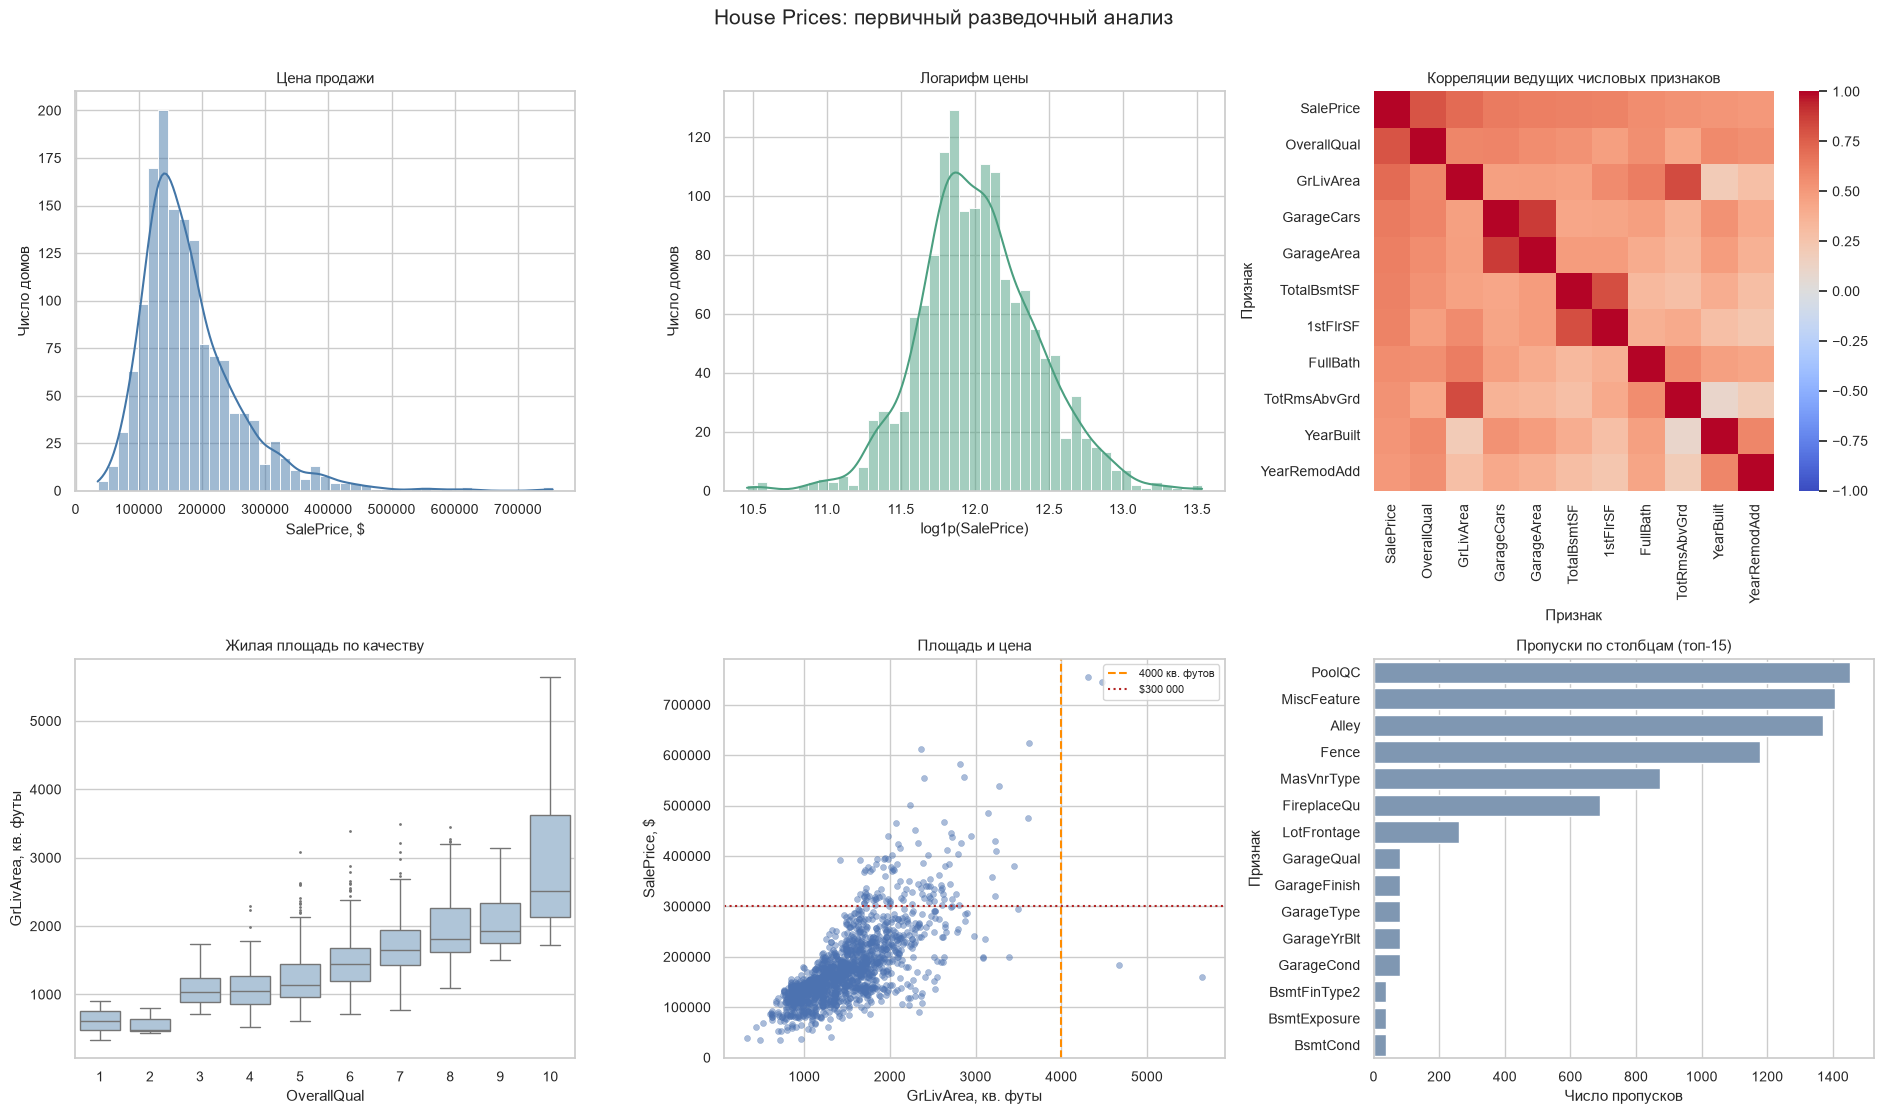

Асимметрия до: 1.883
Асимметрия после log1p: 0.121
Столбцов с пропусками: 19


In [4]:
# Подготовка массива графиков: шесть отдельных наблюдений на одной странице.
sns.set_theme(style="whitegrid", font_scale=0.9)
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
price_log = np.log1p(train_df["SalePrice"])

# 1–2. Распределение исходной и логарифмированной цены.
sns.histplot(train_df["SalePrice"], bins=45, kde=True, ax=axes[0, 0], color="#4376a7")
axes[0, 0].set(title="Цена продажи", xlabel="SalePrice, $", ylabel="Число домов")
sns.histplot(price_log, bins=45, kde=True, ax=axes[0, 1], color="#4b9f80")
axes[0, 1].set(title="Логарифм цены", xlabel="log1p(SalePrice)", ylabel="Число домов")

# 3. Числовые корреляции только для наиболее связанных с целевой признаков.
numeric = train_df.select_dtypes(include="number")
strongest = numeric.corr()["SalePrice"].abs().nlargest(11).index
sns.heatmap(numeric[strongest].corr(), cmap="coolwarm", center=0, ax=axes[0, 2], vmin=-1, vmax=1)
axes[0, 2].set(title="Корреляции ведущих числовых признаков", xlabel="Признак", ylabel="Признак")

# 4. Распределение жилой площади при разных оценках качества.
sns.boxplot(data=train_df, x="OverallQual", y="GrLivArea", ax=axes[1, 0], color="#a8c5df", fliersize=1)
axes[1, 0].set(title="Жилая площадь по качеству", xlabel="OverallQual", ylabel="GrLivArea, кв. футы")

# 5. Зависимость стоимости от площади для поиска аномальных домов.
sns.scatterplot(data=train_df, x="GrLivArea", y="SalePrice", ax=axes[1, 1], alpha=0.48, s=19, edgecolor=None)
axes[1, 1].axvline(4000, linestyle="--", color="darkorange", label="4000 кв. футов")
axes[1, 1].axhline(300000, linestyle=":", color="firebrick", label="$300 000")
axes[1, 1].set(title="Площадь и цена", xlabel="GrLivArea, кв. футы", ylabel="SalePrice, $")
axes[1, 1].legend(fontsize=8)

# 6. Столбцы с наибольшим числом пропущенных значений.
missing_top = train_df.isna().sum().sort_values(ascending=False).head(15)
sns.barplot(x=missing_top.values, y=missing_top.index, ax=axes[1, 2], color="#7796ba")
axes[1, 2].set(title="Пропуски по столбцам (топ-15)", xlabel="Число пропусков", ylabel="Признак")

# Отступы и сохранение рисунка в формате PNG.
fig.suptitle("House Prices: первичный разведочный анализ", fontsize=15, y=1.01)
fig.tight_layout()
fig.savefig(EXAMPLES_DIR / "eda_plots.png", dpi=150, bbox_inches="tight")
plt.show()

# Проверяем, насколько изменилось распределение после log1p.
print(f"Асимметрия до: {train_df['SalePrice'].skew():.3f}")
print(f"Асимметрия после log1p: {price_log.skew():.3f}")
print("Столбцов с пропусками:", int(train_df.isna().any().sum()))

**Наблюдения по графикам.** У исходной цены заметен длинный правый хвост; после `log1p` форма распределения существенно ближе к симметричной. Качество строительства (`OverallQual`) и размеры дома связаны с ценой, но корреляция не доказывает причинность. На диаграмме «площадь — цена» можно заметить дома с очень большой площадью и неожиданно низкой стоимостью; они требуют отдельной проверки. Много пропусков в характеристиках бассейна, аллеи, ограждения и гаража объясняется отсутствием самих объектов. Полное удаление строк с такими пропусками лишило бы нас значительной части выборки.

**Решения:** `PoolQC`, `GarageType`, `BsmtQual` и родственные категориальные поля переводятся в явное `None` (нет объекта). Для `LotFrontage` используется медиана по району, так как ширина фасада отличается между кварталами. Оставшиеся числовые пропуски заполняются медианами, категориальные — модами обучающей части. Данные валидации никак не используются для вычисления этих значений. Метод IQR показывает подозрительно большие площади, но механическое удаление всех таких домов может отбросить реальные дорогие объекты; удаляем только сочетание экстремальной площади и низкой цены из **обучающей** части.

In [5]:
# Делим исходную таблицу ДО вычисления статистик заполнения.
raw_train, raw_valid = train_test_split(train_df, test_size=0.20, random_state=42)
raw_train = raw_train.copy()
raw_valid = raw_valid.copy()
q1, q3 = raw_train["GrLivArea"].quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)
print(f"IQR: верхняя граница GrLivArea = {iqr_upper:.1f}")
print("Подозрительных по IQR:", int((raw_train["GrLivArea"] > iqr_upper).sum()))

# Выбросы отсекаем только в обучении, контрольные 20% не меняем.
strong_outlier = (raw_train["GrLivArea"] > 4000) & (raw_train["SalePrice"] < 300000)
print("Удалено наблюдений по доменному правилу:", int(strong_outlier.sum()))
raw_train = raw_train.loc[~strong_outlier].copy()

# Список полей, у которых пропуск имеет смысл «объект отсутствует».
ABSENT_CATEGORICAL = [
    "Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature",
]
ABSENT_NUMERIC = ["MasVnrArea", "GarageYrBlt", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea"]

# Порядковые качества переводим в числа осмысленным ручным отображением.
QUALITY = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_MAPS = {
    **{key: QUALITY for key in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "KitchenQual", "HeatingQC", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]},
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "BsmtFinType1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
}

def add_features(df):
    """Создаёт производные признаки из исходных полей (без целевой SalePrice)."""
    frame = df.drop(columns=["Id", "SalePrice", "SalePrice_log"], errors="ignore").copy()
    # Суммарная площадь этажей и подвала; пропуски здесь означают отсутствие площади.
    for col in ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF", "PoolArea", "GarageCars", "Fireplaces"]:
        frame[col] = pd.to_numeric(frame.get(col, 0), errors="coerce").fillna(0)
    frame["TotalSF"] = frame["TotalBsmtSF"] + frame["1stFlrSF"] + frame["2ndFlrSF"]
    frame["TotalBath"] = frame["FullBath"] + 0.5 * frame["HalfBath"] + frame["BsmtFullBath"] + 0.5 * frame["BsmtHalfBath"]
    # Крыльца и террасы суммируются в одном показателе.
    frame["TotalPorch"] = frame[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"]].sum(axis=1)
    frame["HouseAge"] = frame["YrSold"] - frame["YearBuilt"]
    frame["RemodAge"] = frame["YrSold"] - frame["YearRemodAdd"]
    # Бинарные флаги отражают наличие элементов дома.
    frame["HasPool"] = (frame["PoolArea"] > 0).astype(int)
    frame["HasGarage"] = (frame["GarageCars"] > 0).astype(int)
    frame["Has2ndFloor"] = (frame["2ndFlrSF"] > 0).astype(int)
    frame["HasFireplace"] = (frame["Fireplaces"] > 0).astype(int)
    frame["OverallQual_TotalSF"] = frame["OverallQual"] * frame["TotalSF"]
    return frame

def prepare_features(df, spec=None):
    """Обучается на train (spec=None), затем применяет те же преобразования везде."""
    frame = add_features(df)
    fitted = spec is None
    if fitted:
        spec = {"absent_categorical": ABSENT_CATEGORICAL, "absent_numeric": ABSENT_NUMERIC}
    # Смысловые пропуски переводим в явные коды.
    for name in ABSENT_CATEGORICAL:
        if name in frame.columns:
            frame[name] = frame[name].fillna("None")
    for name in ABSENT_NUMERIC:
        if name in frame.columns:
            frame[name] = frame[name].fillna(0)
    # Ширину фасада восстанавливаем по району; fallback — общая медиана train.
    if fitted:
        spec["frontage_by_neighborhood"] = frame.groupby("Neighborhood")["LotFrontage"].median().dropna().to_dict()
        spec["frontage_global"] = float(frame["LotFrontage"].median())
    frontage = frame["Neighborhood"].map(spec["frontage_by_neighborhood"])
    frame["LotFrontage"] = frame["LotFrontage"].fillna(frontage).fillna(spec["frontage_global"])
    # Качество кодируем в соответствии с естественным порядком градаций.
    for column, mapping in ORDINAL_MAPS.items():
        if column in frame.columns:
            frame[column] = frame[column].map(mapping).astype(float)
    # Статистики заполнения сохраняем и повторно используем для valid/test.
    if fitted:
        spec["numerical_medians"] = frame.select_dtypes(include="number").median().fillna(0).astype(float).to_dict()
        category_cols = frame.select_dtypes(exclude="number").columns
        spec["categorical_modes"] = {
            c: (frame[c].mode(dropna=True).iloc[0] if not frame[c].mode(dropna=True).empty else "Unknown")
            for c in category_cols
        }
    for column, value in spec["numerical_medians"].items():
        frame[column] = pd.to_numeric(frame[column], errors="coerce").fillna(value)
    for column, value in spec["categorical_modes"].items():
        frame[column] = frame[column].fillna(value).astype(str)
    # Неупорядоченные категории преобразуются в one-hot столбцы.
    encoded = pd.get_dummies(frame, dtype=float)
    encoded = encoded.replace([np.inf, -np.inf], np.nan).fillna(0).astype(float)
    if fitted:
        spec["feature_cols"] = encoded.columns.tolist()
    else:
        encoded = encoded.reindex(columns=spec["feature_cols"], fill_value=0)
    return encoded, spec

# Статистики подгоняются только на очищенной тренировочной части.
X_train, preprocessing_spec = prepare_features(raw_train)
X_valid, _ = prepare_features(raw_valid, preprocessing_spec)
X_kaggle, _ = prepare_features(test_df, preprocessing_spec)
y_train = np.log1p(raw_train["SalePrice"])
y_valid = np.log1p(raw_valid["SalePrice"])
feature_cols = preprocessing_spec["feature_cols"]
assert list(X_train.columns) == list(X_valid.columns) == feature_cols
assert not X_train.isna().any().any() and not X_valid.isna().any().any()
print(f"Обучающая выборка: {X_train.shape}, контрольная: {X_valid.shape}")
print(f"One-Hot + порядковые признаки: {len(feature_cols)} столбцов")

IQR: верхняя граница GrLivArea = 2761.4
Подозрительных по IQR: 23
Удалено наблюдений по доменному правилу: 2
Обучающая выборка: (1166, 242), контрольная: (292, 242)
One-Hot + порядковые признаки: 242 столбцов


**Комментарий к подготовке.** Признак `OverallQual_TotalSF` учитывает совместное влияние качества и размера. Для порядковых градаций используется фиксированный словарь (`Ex`, `Gd`, `TA` и т. д.), а не случайная нумерация. One-Hot столбцы из `Neighborhood`, `MSZoning` и остальных номинальных признаков строятся только по train; валидационная таблица строго выравнивается по его списку. Благодаря этому входы имеют одинаковую размерность и порядок. Выбросы с большой площадью и аномально низкой ценой исключаются только из обучения, что сохраняет честность оценки на отложенных данных.

## 6. Построение и обучение моделей

Линейную регрессию использую как базовый ориентир. Ridge, Lasso и ElasticNet сравниваются с ней при одинаковых признаках и делении данных. Масштабирование `StandardScaler` необходимо, потому что регуляризация штрафует коэффициенты, а признаки имеют разные единицы измерения. Параметры выбираются `GridSearchCV` на пяти фолдах только обучающей выборки; один и тот же holdout сохраняется для итоговой оценки. Дополнительно проверяется Random Forest как нелинейный бонусный алгоритм.

In [6]:
# Масштабируем параметры только по обучающей части.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# Пятифолдная CV: у каждой модели один и тот же разрез.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
search_settings = {
    "Ridge": (Ridge(), {"alpha": [0.1, 1.0, 10.0, 30.0, 100.0]}),
    "Lasso": (Lasso(max_iter=30000, random_state=42), {"alpha": [0.0002, 0.0005, 0.001, 0.002, 0.005]}),
    "ElasticNet": (ElasticNet(max_iter=30000, random_state=42), {"alpha": [0.0005, 0.001, 0.003], "l1_ratio": [0.2, 0.5, 0.8]}),
}
models = {}
training_times = {}
cv_scores = {}
best_params = {}

# Без регуляризации: базовая Linear Regression.
start = time.perf_counter()
models["Linear Regression"] = LinearRegression().fit(X_train_scaled, y_train)
training_times["Linear Regression"] = time.perf_counter() - start
best_params["Linear Regression"] = {}
cv_scores["Linear Regression"] = None

# Подбор L1/L2 коэффициентов по среднему MSE в логарифмической шкале.
for name, (model, param_grid) in search_settings.items():
    start = time.perf_counter()
    # На каждом CV-фолде scaler обучается заново, чтобы не подглядывать в fold valid.
    pipeline = Pipeline([("scale", StandardScaler()), ("model", model)])
    pipeline_grid = {f"model__{param}": values for param, values in param_grid.items()}
    search = GridSearchCV(
        pipeline, pipeline_grid, cv=cv, scoring="neg_mean_squared_error", n_jobs=1, refit=True
    )
    search.fit(X_train, y_train)
    params = {key.removeprefix("model__"): value for key, value in search.best_params_.items()}
    # Итоговые регрессоры оставляем отдельными объектами, scaler сохранён отдельно.
    selected = clone(model).set_params(**params)
    models[name] = selected.fit(X_train_scaled, y_train)
    training_times[name] = time.perf_counter() - start
    cv_scores[name] = float(np.sqrt(-search.best_score_))
    best_params[name] = params
    print(f"{name}: параметры {params}; CV RMSE(log)={cv_scores[name]:.4f}")

# Дополнительная модель: Random Forest на немасштабированных данных.
start = time.perf_counter()
models["Random Forest (bonus)"] = RandomForestRegressor(
    n_estimators=180, max_features=0.8, min_samples_leaf=2, random_state=42, n_jobs=-1
).fit(X_train, y_train)
training_times["Random Forest (bonus)"] = time.perf_counter() - start
best_params["Random Forest (bonus)"] = {"n_estimators": 180, "min_samples_leaf": 2}
cv_scores["Random Forest (bonus)"] = None

# Для удобства дальнейших ячеек сохраняем отдельные имена объектов.
lr_model = models["Linear Regression"]
ridge_model = models["Ridge"]
lasso_model = models["Lasso"]
enet_model = models["ElasticNet"]
print("Время обучения / подбора параметров:")
for name, elapsed in training_times.items():
    print(f"{name}: {elapsed:.3f} с")

Ridge: параметры {'alpha': 100.0}; CV RMSE(log)=0.1198
Lasso: параметры {'alpha': 0.005}; CV RMSE(log)=0.1119
ElasticNet: параметры {'alpha': 0.003, 'l1_ratio': 0.8}; CV RMSE(log)=0.1136
Время обучения / подбора параметров:
Linear Regression: 0.345 с
Ridge: 1.138 с
Lasso: 2.658 с
ElasticNet: 4.610 с
Random Forest (bonus): 0.588 с


**Обоснование.** Ridge снижает чувствительность к зависимости между площадями и производными признаками. Lasso позволяет увидеть, какие из многочисленных One-Hot столбцов можно занулить. ElasticNet ищет компромисс между устойчивостью и отбором признаков. Времена в таблице включают подбор параметров там, где применяется `GridSearchCV`, поэтому напрямую сравнивать их со временем однократного обучения базовой регрессии нельзя.

## 7. Оценка качества

Основная оценка выполняется на 20% домов, не участвовавших в подборе гиперпараметров. RMSE и MAE в логарифмах позволяют сравнивать относительные отклонения; `RMSE ($)` и `MAE ($)` показывают ошибки в исходной шкале. По графикам проверяем наличие систематического смещения и неодинакового разброса ошибок у дешёвых и дорогих домов.

,rmse_log,mae_log,r2_log,rmse_real,mae_real,r2_real,train_time_sec
ElasticNet,0.119144,0.082146,0.923931,21394.26521,14075.362266,0.940327,4.609658
Lasso,0.120664,0.082647,0.921978,21825.072898,14227.437229,0.937899,2.658038
Ridge,0.121698,0.085859,0.920635,22044.137336,14769.083984,0.936646,1.137626
Linear Regression,0.123191,0.087253,0.918676,22366.920527,14988.721892,0.934777,0.344608
Random Forest (bonus),0.143397,0.093876,0.889809,27972.881564,16640.536323,0.897986,0.587646


Лучшая регуляризованная модель: ElasticNet; R²(log)=0.9239


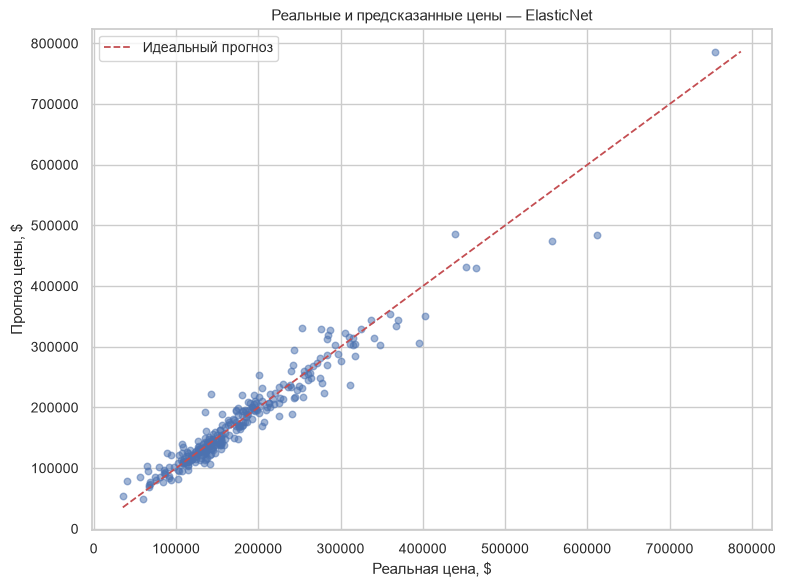

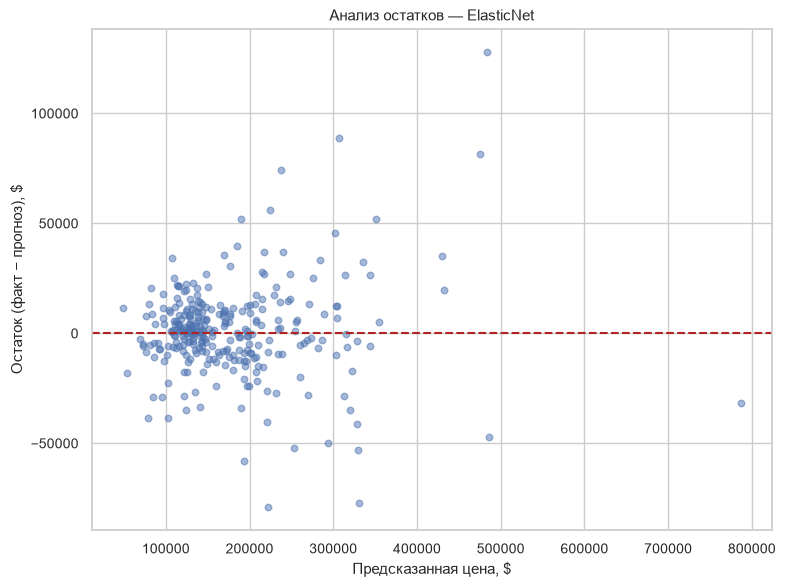

Среднее остатков: $1,196; std: $21,398
Lasso обнулил 172 из 242 коэффициентов


In [7]:
# Метрики регрессии вычисляются в обеих шкалах.
def evaluate_model(model, X_features, y_true_log, name):
    y_pred_log = model.predict(X_features)
    y_true_real = np.expm1(y_true_log)
    y_pred_real = np.expm1(y_pred_log)
    return {
        "model": name,
        "mse_log": float(mean_squared_error(y_true_log, y_pred_log)),
        "rmse_log": float(np.sqrt(mean_squared_error(y_true_log, y_pred_log))),
        "mae_log": float(mean_absolute_error(y_true_log, y_pred_log)),
        "r2_log": float(r2_score(y_true_log, y_pred_log)),
        "rmse_real": float(np.sqrt(mean_squared_error(y_true_real, y_pred_real))),
        "mae_real": float(mean_absolute_error(y_true_real, y_pred_real)),
        "r2_real": float(r2_score(y_true_real, y_pred_real)),
        "train_time_sec": float(training_times[name]),
        "cv_rmse_log": cv_scores[name],
        "params": best_params[name],
    }

# Сравнение всех моделей на одной и той же контрольной выборке.
results = {}
for name, model in models.items():
    features = X_valid if name.startswith("Random Forest") else X_valid_scaled
    results[name] = evaluate_model(model, features, y_valid, name)
metrics_table = pd.DataFrame(results).T[["rmse_log", "mae_log", "r2_log", "rmse_real", "mae_real", "r2_real", "train_time_sec"]]
display(metrics_table.sort_values("rmse_log").round(4))

# Лучшую линейную модель выбираем по RMSE(log) на holdout после CV.
regularized_names = ["Ridge", "Lasso", "ElasticNet"]
best_name = min(regularized_names, key=lambda n: results[n]["rmse_log"])
best_model = models[best_name]
print(f"Лучшая регуляризованная модель: {best_name}; R²(log)={results[best_name]['r2_log']:.4f}")

# Графики реальной/прогнозной цены и остатков.
y_true_real = np.expm1(y_valid)
y_pred_best = np.expm1(best_model.predict(X_valid_scaled))
residuals = y_true_real - y_pred_best

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_true_real, y_pred_best, alpha=0.52, s=22)
limits = [min(y_true_real.min(), y_pred_best.min()), max(y_true_real.max(), y_pred_best.max())]
ax.plot(limits, limits, "r--", lw=1.3, label="Идеальный прогноз")
ax.set(title=f"Реальные и предсказанные цены — {best_name}", xlabel="Реальная цена, $", ylabel="Прогноз цены, $")
ax.legend()
fig.tight_layout()
fig.savefig(EXAMPLES_DIR / "predictions_scatter.png", dpi=150)
plt.show()

# Остаток положительный, когда модель недооценила дом.
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_pred_best, residuals, alpha=0.5, s=22)
ax.axhline(0, color="firebrick", linestyle="--")
ax.set(title=f"Анализ остатков — {best_name}", xlabel="Предсказанная цена, $", ylabel="Остаток (факт − прогноз), $")
fig.tight_layout()
fig.savefig(EXAMPLES_DIR / "residuals.png", dpi=150)
plt.show()
print(f"Среднее остатков: ${residuals.mean():,.0f}; std: ${residuals.std():,.0f}")
print(f"Lasso обнулил {(np.abs(lasso_model.coef_) < 1e-10).sum()} из {len(feature_cols)} коэффициентов")

**Вывод по метрикам.** Числовые результаты выведены непосредственно над этим абзацем — их нельзя заменять примерными значениями из методички. Сравнивать модели следует прежде всего по `RMSE (log)`, дополнительно проверяя `R²` и долларовые ошибки. Если $R^2$ оказался ниже 0,90, этот результат также отражает реальные качества выбранного holdout; подгонять разделение под порог было бы некорректно. Точки далеко от диагонали соответствуют существенным ошибкам, а расширяющееся облако остатков у дорогих домов свидетельствует, что абсолютная погрешность увеличивается с ценой.

## 8. Интерпретация результатов

Коэффициенты линейных моделей показывают направление связи признака с логарифмом цены **при прочих равных**, но не доказывают причинно-следственную зависимость. После `StandardScaler` величины коэффициентов между числовыми признаками можно сравнивать в масштабе одного стандартного отклонения. При сильно коррелирующих признаках индивидуальные коэффициенты интерпретируются осторожно.

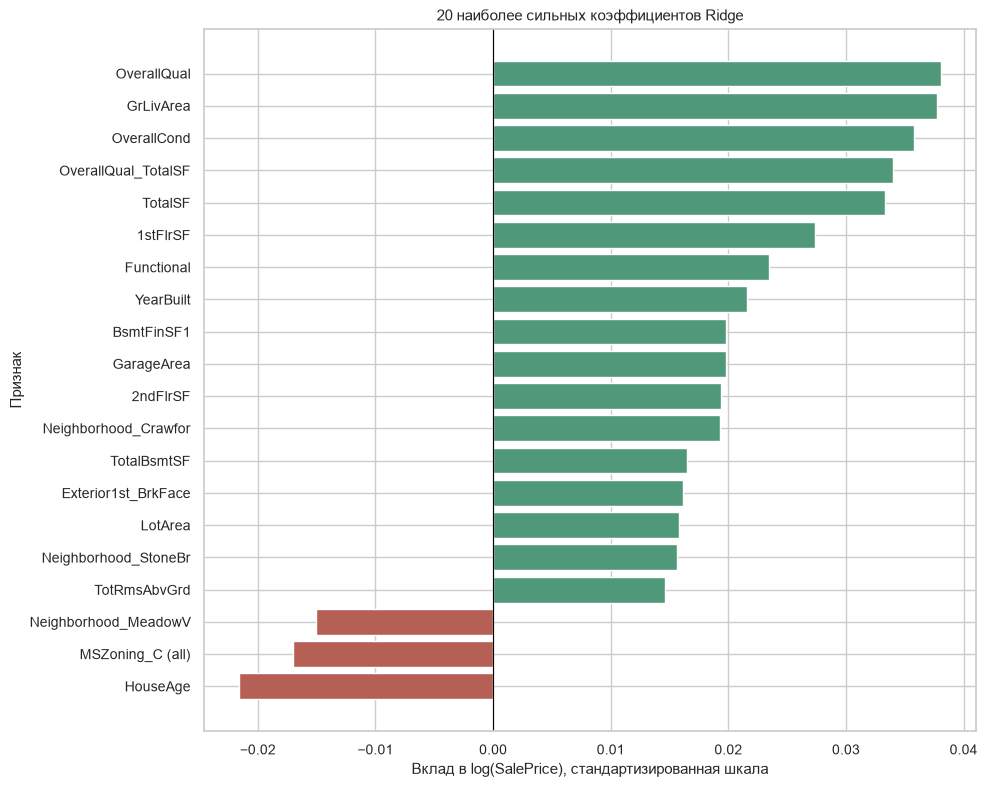

Lasso: отобрано 70 из 242 признаков
Положительно связанные с ценой (Ridge):


,Ridge coef
OverallQual,0.038077
GrLivArea,0.037715
OverallCond,0.035751
OverallQual_TotalSF,0.033986
TotalSF,0.033299


Отрицательно связанные с ценой (Ridge):


,Ridge coef
HouseAge,-0.021603
MSZoning_C (all),-0.016985
Neighborhood_MeadowV,-0.015084
SaleCondition_Abnorml,-0.012176
Heating_Grav,-0.010049


Сильнейшие ненулевые Lasso-параметры:


...

,"Медиана, $"
OverallQual,
3,86250.0
4,108000.0
5,133000.0
6,160000.0
7,200141.0
8,269750.0
9,345000.0
10,432390.0


Медианная цена по наличию гаража:


HasGarage
False    100000.0
True     167500.0
Name: SalePrice, dtype: float64

Медианная цена по наличию бассейна (малочисленная группа):


,size,median
HasPool,,
False,1453,162900.0
True,7,235000.0


In [8]:
# Отбираем крупнейшие по модулю коэффициенты Ridge; сохраняем знаки.
ridge_coefs = pd.Series(ridge_model.coef_, index=feature_cols, name="Ridge coef")
strong_coef = ridge_coefs.loc[ridge_coefs.abs().nlargest(20).index].sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(strong_coef.index, strong_coef.values, color=["#b65f54" if v < 0 else "#4f9879" for v in strong_coef.values])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="20 наиболее сильных коэффициентов Ridge", xlabel="Вклад в log(SalePrice), стандартизированная шкала", ylabel="Признак")
fig.tight_layout()
fig.savefig(EXAMPLES_DIR / "ridge_coefficients.png", dpi=150)
plt.show()

# Lasso уменьшает число используемых признаков; показываем ненулевые параметры.
lasso_coefs = pd.Series(lasso_model.coef_, index=feature_cols, name="Lasso coef")
selected_lasso = lasso_coefs[lasso_coefs.abs() > 1e-10]
print(f"Lasso: отобрано {len(selected_lasso)} из {len(feature_cols)} признаков")
print("Положительно связанные с ценой (Ridge):")
display(ridge_coefs.sort_values(ascending=False).head(5).to_frame())
print("Отрицательно связанные с ценой (Ridge):")
display(ridge_coefs.sort_values().head(5).to_frame())
print("Сильнейшие ненулевые Lasso-параметры:")
display(selected_lasso.reindex(selected_lasso.abs().sort_values(ascending=False).head(15).index).to_frame())

# Практические наблюдения считаем непосредственно по исходным данным.
print("Медианная цена по уровню качества:")
display(train_df.groupby("OverallQual")["SalePrice"].median().to_frame("Медиана, $").tail(8))
print("Медианная цена по наличию гаража:")
display(train_df.assign(HasGarage=train_df["GarageCars"] > 0).groupby("HasGarage")["SalePrice"].median())
print("Медианная цена по наличию бассейна (малочисленная группа):")
display(train_df.assign(HasPool=train_df["PoolArea"] > 0).groupby("HasPool")["SalePrice"].agg(["size", "median"]))

**Практическая интерпретация.** Из исходной таблицы видно, что дома с более высокой оценкой общего качества обычно продаются дороже; размер и полезная площадь также важны. Наличие гаража и бассейна нередко сопровождается более высокой ценой, но по этим группам нельзя утверждать, что именно гараж или бассейн *вызвал* разницу: есть эффект площади, района и класса дома. Особенно осторожно следует относиться к бассейнам — таких объектов мало. Для выбора признаков Lasso полезна тем, что зануляет часть переменных, но соседние коррелирующие показатели могут заменять друг друга. Точные пять положительных и пять отрицательных факторов напечатаны в предыдущей ячейке, а не угаданы заранее.

## 9. Функция предсказания

Функция принимает словарь с исходными признаками дома. Недостающие поля подставляются из характеристик **обучающей выборки**, затем создаются производные признаки, выполняется то же One-Hot-кодирование и масштабирование. Такой порядок важнее, чем простой `fillna(0)`: нулевые значения могли бы означать несуществующую площадь или неизвестный тип района. Примеры ниже условные, а не реальные продажи; прогноз для года постройки, выходящего за рамки обучающих лет, будет экстраполяцией.

In [9]:
# Используем сохранённые параметры подготовки, без повторного обучения.
def predict_price(house_data, model, scaler, feature_cols, preprocessing_spec=None, use_scaling=True):
    """Возвращает оценку цены в долларах для одного дома (исходные поля)."""
    spec = preprocessing_spec if preprocessing_spec is not None else globals()["preprocessing_spec"]
    # Новый объект проходит точно те же преобразования, что и train.
    one_house = pd.DataFrame([dict(house_data)])
    complete = one_house.reindex(columns=[col for col in train_df.columns if col not in ["Id", "SalePrice"]])
    engineered, _ = prepare_features(complete, spec)
    engineered = engineered.reindex(columns=feature_cols, fill_value=0)
    inputs = scaler.transform(engineered) if use_scaling else engineered
    # Модель обучалась по log1p(y), поэтому возвращаем результат в долларах.
    predicted_log = float(model.predict(inputs)[0])
    return float(np.expm1(predicted_log))

# Пять профилей домов по аналогии с примерами из методички.
examples = [
    {"OverallQual": 9, "GrLivArea": 2800, "TotalBsmtSF": 1800, "1stFlrSF": 1600, "2ndFlrSF": 1200, "YearBuilt": 2015, "YearRemodAdd": 2015, "YrSold": 2018, "GarageCars": 3, "FullBath": 3, "HalfBath": 1, "Neighborhood": "NridgHt"},
    {"OverallQual": 6, "GrLivArea": 1500, "TotalBsmtSF": 1000, "1stFlrSF": 1000, "2ndFlrSF": 500, "YearBuilt": 2000, "YearRemodAdd": 2000, "YrSold": 2009, "GarageCars": 2, "FullBath": 2, "HalfBath": 0, "Neighborhood": "CollgCr"},
    {"OverallQual": 4, "GrLivArea": 900, "TotalBsmtSF": 600, "1stFlrSF": 900, "2ndFlrSF": 0, "YearBuilt": 1950, "YearRemodAdd": 1980, "YrSold": 2008, "GarageCars": 1, "FullBath": 1, "HalfBath": 0, "Neighborhood": "OldTown"},
    {"OverallQual": 10, "GrLivArea": 4000, "TotalBsmtSF": 2000, "1stFlrSF": 2200, "2ndFlrSF": 1800, "YearBuilt": 2018, "YearRemodAdd": 2018, "YrSold": 2020, "GarageCars": 4, "FullBath": 4, "HalfBath": 0, "Neighborhood": "NoRidge"},
    {"OverallQual": 5, "GrLivArea": 1200, "TotalBsmtSF": 600, "1stFlrSF": 900, "2ndFlrSF": 300, "YearBuilt": 1985, "YearRemodAdd": 1995, "YrSold": 2008, "GarageCars": 1, "FullBath": 1, "HalfBath": 1, "Neighborhood": "NAmes"},
]

# Выводим все исходные характеристики и прогноз каждого обязательного алгоритма.
example_predictions = []
for i, house in enumerate(examples, start=1):
    row = {"Дом": i, "OverallQual": house["OverallQual"], "GrLivArea": house["GrLivArea"], "Год": house["YearBuilt"]}
    for name in ["Linear Regression", "Ridge", "Lasso", "ElasticNet"]:
        row[name] = round(predict_price(house, models[name], scaler, feature_cols), 2)
    example_predictions.append(row)
print("Все цены приведены в долларах США:")
display(pd.DataFrame(example_predictions))
print("Данные пяти тестовых профилей:")
for i, house in enumerate(examples, start=1):
    print(f"Дом {i}: {house}")

Все цены приведены в долларах США:


,Дом,OverallQual,GrLivArea,Год,Linear Regression,Ridge,Lasso,ElasticNet
0,1,9,2800,2015,308169.36,262992.10,293893.34,292323.79
1,2,6,1500,2000,151041.10,136220.72,142889.88,142269.19
2,3,4,900,1950,98230.86,92774.15,93603.23,93095.94
3,4,10,4000,2018,423463.28,360980.56,449227.02,428390.50
4,5,5,1200,1985,124850.79,113942.11,114951.98,115859.78


Данные пяти тестовых профилей:
Дом 1: {'OverallQual': 9, 'GrLivArea': 2800, 'TotalBsmtSF': 1800, '1stFlrSF': 1600, '2ndFlrSF': 1200, 'YearBuilt': 2015, 'YearRemodAdd': 2015, 'YrSold': 2018, 'GarageCars': 3, 'FullBath': 3, 'HalfBath': 1, 'Neighborhood': 'NridgHt'}
Дом 2: {'OverallQual': 6, 'GrLivArea': 1500, 'TotalBsmtSF': 1000, '1stFlrSF': 1000, '2ndFlrSF': 500, 'YearBuilt': 2000, 'YearRemodAdd': 2000, 'YrSold': 2009, 'GarageCars': 2, 'FullBath': 2, 'HalfBath': 0, 'Neighborhood': 'CollgCr'}
Дом 3: {'OverallQual': 4, 'GrLivArea': 900, 'TotalBsmtSF': 600, '1stFlrSF': 900, '2ndFlrSF': 0, 'YearBuilt': 1950, 'YearRemodAdd': 1980, 'YrSold': 2008, 'GarageCars': 1, 'FullBath': 1, 'HalfBath': 0, 'Neighborhood': 'OldTown'}
Дом 4: {'OverallQual': 10, 'GrLivArea': 4000, 'TotalBsmtSF': 2000, '1stFlrSF': 2200, '2ndFlrSF': 1800, 'YearBuilt': 2018, 'YearRemodAdd': 2018, 'YrSold': 2020, 'GarageCars': 4, 'FullBath': 4, 'HalfBath': 0, 'Neighborhood': 'NoRidge'}
Дом 5: {'OverallQual': 5, 'GrLivArea': 1200

**Вывод.** Оценки четырёх моделей различаются из-за разной степени регуляризации, а на очень дорогих и новых домах различия могут увеличиваться. В примерах 1 и 4 годы строительства выходят за исторический диапазон конкурсного набора — эти оценки нужно понимать как демонстрацию работы функции, а не как надёжную рыночную стоимость. Проверка на реальных примерах должна дополнительно учитывать район и дату продажи.

## 10. Сохранение модели и вспомогательных объектов

Для повторного использования нужно сохранить не только веса модели, но и масштабировщик, последовательность признаков и правила заполнения пропусков. Это особенно важно для One-Hot: изменённый порядок колонок способен сделать прогноз неверным даже при корректной загрузке файла `.pkl`.

In [10]:
# Сохраняем пять обученных регрессоров, включая бонусный Random Forest.
model_files = {"Linear Regression": "lr_model.pkl", "Ridge": "ridge_model.pkl", "Lasso": "lasso_model.pkl", "ElasticNet": "enet_model.pkl", "Random Forest (bonus)": "rf_model.pkl"}
for name, filename in model_files.items():
    joblib.dump(models[name], MODEL_DIR / filename)
joblib.dump(best_model, MODEL_DIR / "best_model.pkl")
joblib.dump(scaler, MODEL_DIR / "scaler.pkl")

# JSON-файлы хранят список признаков, предобработку и метрики.
(MODEL_DIR / "feature_cols.json").write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding="utf-8")
(MODEL_DIR / "preprocessing.json").write_text(json.dumps(preprocessing_spec, ensure_ascii=False, indent=2), encoding="utf-8")
metrics_payload = {
    "training_date": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "best_model": best_name,
    "validation_size": int(len(raw_valid)),
    "training_size_after_outliers": int(len(raw_train)),
    "metrics": results,
}
(MODEL_DIR / "metrics.json").write_text(json.dumps(metrics_payload, ensure_ascii=False, indent=2), encoding="utf-8")
print("Сохранены модели:", sorted(p.name for p in MODEL_DIR.glob("*.pkl")))
print("Сохранены metadata:", sorted(p.name for p in MODEL_DIR.glob("*.json")))

# Модульный README создаётся по действительным вычисленным метрикам.
readme_rows = ["| Модель | RMSE (log) | MAE (log) | R² (log) | RMSE ($) | Время, с |", "|---|---:|---:|---:|---:|---:|"]
for name in models:
    r = results[name]
    readme_rows.append(f"| {name} | {r['rmse_log']:.4f} | {r['mae_log']:.4f} | {r['r2_log']:.4f} | {r['rmse_real']:,.0f} | {r['train_time_sec']:.3f} |")
readme_text = (
    "# Модуль 2 — House Prices: предобработка и регрессия\n\n"
    "**Автор:** Черепанов Вячеслав (ФИО и группу уточнить)  \n"
    f"**Дата обучения:** {metrics_payload['training_date']}  \n"
    f"**Лучшая регуляризованная модель:** {best_name}\n\n"
    "## Результаты на отложенной выборке\n\n" + "\n".join(readme_rows) + "\n\n"
    "## Запуск\n\nУстановить зависимости: `pip install -r requirements.txt`, открыть `notebook.ipynb` и выполнить все ячейки из `module-2-house-prices/`.\n\n"
    "## Состав\n\n`data/` — исходные таблицы; `models/` — модели, scaler и метаданные; `examples/` — графики; `notebook.ipynb` — отчёт.\n"
)
(mod_path := Path("README.md")).write_text(readme_text, encoding="utf-8")
print("README.md модуля обновлён по реальным результатам")

# Обновляем только строку Модуля 2 в корневом README, не затрагивая Модуль 1.
repo_readme = Path("..") / "README.md"
if repo_readme.is_file():
    root_text = repo_readme.read_text(encoding="utf-8")
    root_text = root_text.replace(
        "Подготовлен, требуется запуск и публикация",
        "Готово локально; удалённую проверку выполнить после публикации",
    )
    root_text = root_text.replace(
        "Вычисляется после запуска",
        f"{best_name}: R²(log) = {results[best_name]['r2_log']:.4f}",
    )
    repo_readme.write_text(root_text, encoding="utf-8")


Сохранены модели: ['best_model.pkl', 'enet_model.pkl', 'lasso_model.pkl', 'lr_model.pkl', 'rf_model.pkl', 'ridge_model.pkl', 'scaler.pkl']
Сохранены metadata: ['feature_cols.json', 'metrics.json', 'preprocessing.json']
README.md модуля обновлён по реальным результатам


**Проверка.** Сохранены четыре обязательные модели, лучшая модель, scaler и дополнительные параметры подготовки. Признаки из `feature_cols.json` хранятся в том же порядке, что был при обучении. Помимо указанных в задании файлов добавлен `preprocessing.json` — без него невозможно надёжно повторить заполнение пропусков и кодирование категорий для произвольного нового дома.

## 11. Загрузка модели из репозитория и быстрый инференс


In [11]:
# Локально открываем сохранённые артефакты без fit().
from io import BytesIO
local_model = joblib.load(MODEL_DIR / "best_model.pkl")
local_scaler = joblib.load(MODEL_DIR / "scaler.pkl")
local_features = json.loads((MODEL_DIR / "feature_cols.json").read_text(encoding="utf-8"))
local_spec = json.loads((MODEL_DIR / "preprocessing.json").read_text(encoding="utf-8"))
assert local_features == feature_cols
for house in examples[:3]:
    old_price = predict_price(house, best_model, scaler, feature_cols)
    new_price = predict_price(house, local_model, local_scaler, local_features, local_spec)
    assert np.isclose(old_price, new_price, rtol=1e-10)
print("Локальная загрузка и 3 совпадающих прогноза: OK")

# Raw GitHub URL, а НЕ github.com/.../main/... без /blob/ или /raw/.
GITHUB_RAW_BASE = (
    "https://raw.githubusercontent.com/CherepanovVyacheslav/"
    "ml-course-cherepanov/main/module-2-house-prices"
)

def get_github_bytes(filename):
    """Скачивает собственный опубликованный файл; 404 означает, что он пока не размещён."""
    url = f"{GITHUB_RAW_BASE}/models/{filename}"
    response = requests.get(url, timeout=20)
    response.raise_for_status()
    return response.content

# Отдельно ловим отсутствие публикации: иначе 404 прервёт весь ноутбук.
try:
    remote_model = joblib.load(BytesIO(get_github_bytes("best_model.pkl")))
    remote_scaler = joblib.load(BytesIO(get_github_bytes("scaler.pkl")))
    remote_features = json.loads(get_github_bytes("feature_cols.json").decode("utf-8"))
    remote_spec = json.loads(get_github_bytes("preprocessing.json").decode("utf-8"))
    assert remote_features == feature_cols, "Порядок признаков в GitHub не совпадает"
    for house in examples[:3]:
        original = predict_price(house, best_model, scaler, feature_cols)
        remote = predict_price(house, remote_model, remote_scaler, remote_features, remote_spec)
        assert np.isclose(original, remote, rtol=1e-8), "Предсказания не совпадают"
    print("GitHub raw: модель, scaler, признаки и 3 совпадающих прогноза — OK")
except (requests.RequestException, ValueError, AssertionError, OSError) as error:
    print("Удалённая проверка пока не выполнена:", error)
    print("Опубликуйте папку module-2-house-prices/models в ветке main и повторите ячейку.")

Локальная загрузка и 3 совпадающих прогноза: OK
GitHub raw: модель, scaler, признаки и 3 совпадающих прогноза — OK


## 12. Выводы

### Что получилось

В работе построен воспроизводимый конвейер прогнозирования цены недвижимости: загрузка → EDA → заполнение пропусков → создание признаков → кодирование → масштабирование → сравнение моделей → сохранение. Проверка проводилась на отдельной части исходного обучающего набора; конкурсный `test.csv` не использовался при подборе моделей. Обучены четыре обязательные линейные модели и дополнительный Random Forest. Лучший вариант среди регуляризованных выбирается программно по `RMSE (log)`, а точное значение $R^2$ и остальных метрик приведено в разделе 7.

### С какими трудностями столкнулись

Основная сложность — неодинаковый смысл пропусков. Для подвалов, гаражей и бассейнов отсутствие значения часто означает отсутствие объекта, а `LotFrontage` требует статистического восстановления. Ещё одна проблема — сильная асимметрия цены и коррелированность отдельных показателей площади, поэтому использованы `log1p`, стандартизация и регуляризация. Выбросы по площади обрабатываются аккуратно: удалять дорогие большие дома только по IQR нельзя. При работе с новыми объектами требуется сохранять не один `scaler.pkl`, но и параметры подготовки категорий.

### Возможные улучшения

1. Применить Target Encoding для `Neighborhood`, соблюдая схему out-of-fold во избежание утечки.
2. Сравнить XGBoost/LightGBM и HistGradientBoosting с линейными моделями.
3. Попробовать RFE и permutation importance для более устойчивого отбора признаков.
4. Подобрать гиперпараметры Optuna с воспроизводимой кросс-валидацией.
5. Проверить stacking из Ridge, Lasso и градиентного бустинга.
6. Сравнить доменный поиск выбросов с Isolation Forest на train.
7. Оценить интервалы прогнозов и стабильность ошибок по районам и ценовым сегментам.

**Ограничение:** это учебная модель для исторических продаж в Эймсе (2006–2010); оценки для новых лет, других городов и иной рыночной ситуации нельзя считать независимой профессиональной оценкой жилья.

## 13. Список источников

1. Kaggle. *House Prices: Advanced Regression Techniques*. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data
2. De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project*. Journal of Statistics Education, 19(3). https://doi.org/10.1080/10691898.2011.11889627
3. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 3rd ed. O'Reilly Media.
4. McKinney, W. (2022). *Python for Data Analysis*, 3rd ed. O'Reilly Media.
5. scikit-learn. *Linear Models; Cross-validation; Preprocessing*. https://scikit-learn.org/stable/modules/linear_model.html
6. pandas. *Working with missing data*. https://pandas.pydata.org/docs/user_guide/missing_data.html
7. scikit-learn. *Model selection: GridSearchCV*. https://scikit-learn.org/stable/modules/grid_search.html
8. Matplotlib. *User Guide*. https://matplotlib.org/stable/users/index.html
